In [11]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
# %% 1. Settings: single and multiple regressions with an arbitrary mean of monthly offsets
import numpy as np
import xarray as xr
from pathlib import Path



ll_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
ll_raw_root = Path("/scratch/leiff/MCA/amip_clean/data")
ll_catalog_path = ll_core / "stationarity/four_region_attribution/run_01/catalog.npy"
ll_output_root = ll_core / "regional_lead_lag"
ll_run_name = "run_02"             # Change for different masks/preprocessing; offsets get their own subfolder.
ll_obs_paths = {"T": ll_raw_root / "ERA5/tas_194001-202412_g025.nc",
                "R": ll_raw_root / "CERES/CERES_net_200003-202604_g025.nc"}
ll_start, ll_end = "2000-03", "2014-12"
ll_experiments = ["historical_matched", "amip_hist"]
ll_fits = {"SEP": ["SEP"], "WPWP": ["WPWP"], "Nino34": ["Nino34"],
           "Nino34_SEP": ["Nino34", "SEP"], "Nino34_WPWP": ["Nino34", "WPWP"],
           "Nino34_SEP_WPWP": ["Nino34", "SEP", "WPWP"]}

# A list describes ONE equally weighted response mean, NOT separate lag fits.
# Convention: x at t, y = mean(field at t + each offset). Positive = field AFTER
# the index; negative = field BEFORE it. All predictors remain at the SAME t.
# ll_offsets = list(range(-12, 13, 2))  # 13 selected months: -12, -10, ..., 10, 12.
# ll_offsets = [-5]                  # Single month: field LEADS index by 5 months.
# ll_offsets = [5]                   # Single month: index LEADS field by 5 months.
# ll_offsets = list(range(12))       # Reproduce the original lag-0-through-11 forward year.
ll_offsets = list(range(-12, 13))   # All 25 months from -12 through +12, including t.
# ll_offsets = [-12, 12]             # Just TWO months, not all months between the bounds.
ll_ocean_mask = None                # Optional True/1=ocean mask refining Nino34 only.
# For your 1=land / NaN=ocean convention: ll_ocean_mask = np.isnan(mask["split_50"].values).
ll_map_mask = None                  # Optional fixed (lat,lon) True/1 RESPONSE mask.
ll_save, ll_resume = True, True
ll_save_response_series = False     # Optional large raw/processed y in model checkpoints.
ll_preprocessing_tag = "monthly_detrend_after_aligned_offset_means_v1"
ll_warn_condition, ll_max_condition = 30., 1e6
ll_plot_statistic = "regression"    # Or "partial_covariance" or marginal "covariance".
ll_plot_vlims = None                # Or [T_limit, R_limit], shared across all figures.
ll_plot_pairs = None                # None = all 10 coefficients; or e.g. [("Nino34_SEP", "SEP")].
ll_save_figures, ll_cmap, ll_font_scale = True, "RdBu_r", 1.

# Separate lag selections cannot overwrite one another. The short folder tag
# represents the EXACT selected offsets, not just their minimum and maximum.
import hashlib
ll_offset_tag = "offsets_" + hashlib.sha256(
    ",".join(str(offset) for offset in sorted(ll_offsets)).encode()).hexdigest()[:12]
ll_output_dir = ll_output_root / ll_offset_tag / ll_run_name
ll_archive_path = ll_output_dir / "regional_lead_lag.npy"

# Import/paste YOUR detrend_monthly_fast before cell 4. Its input is time-first
# and may begin in any calendar month after alignment. It must support partial
# endpoint years. We validate removal of each repeated month's mean and trend.
# Unlike the previous multiple-regression notebook, this reads raw inputs:
# changing offsets changes both y and the valid dates on which x/y are processed.
# All raw averaging/alignment comes BEFORE monthly detrending/deseasonalization.
# Calculate/save: cells 1–6. Load/plot only: cells 1, 7, 8, 9.




In [13]:
# %% 2. Input, mask and atomic-save helpers (the calculation is in cell 3)
def ll_source_mask(lat, lon, weights, ocean_mask=None):
    """Niño-3.4 grid centers: 5S–5N, 170W–120W (190E–240E).

    Longitude may be -180..180 or 0..360. An optional fixed ocean mask refines
    the box without restricting the global response maps. No automatic coast
    data downloads or inferred land masks are used.
    """
    lat, lon, weights = [np.asarray(v, dtype=float) for v in [lat, lon, weights]]
    if lat.ndim != 1 or lon.ndim != 1 or weights.shape != (len(lat), len(lon)):
        raise ValueError("Expected 1-D lat/lon and matching 2-D area weights.")
    if not np.isfinite(lat).all() or not np.isfinite(lon).all():
        raise ValueError("Latitude/longitude must be finite.")
    east_lon = lon % 360
    box = (np.abs(lat[:, None]) <= 5) & ((east_lon >= 190) & (east_lon <= 240))[None, :]
    selected = box & np.isfinite(weights) & (weights > 0)
    if ocean_mask is not None:
        if isinstance(ocean_mask, xr.DataArray):
            ocean_mask = ocean_mask.transpose("lat", "lon")
            for dimension, expected in [("lat", lat), ("lon", lon)]:
                if not np.array_equal(ocean_mask[dimension].values, expected):
                    raise ValueError(f"Ocean mask {dimension} does not match the source grid.")
        ocean = np.ma.asarray(ocean_mask, dtype=float).filled(np.nan)
        if ocean.shape != selected.shape or np.any(np.isfinite(ocean) & (ocean != 0) & (ocean != 1)):
            raise ValueError("Ocean mask must match (lat,lon), with True/1=ocean and False/0/NaN=excluded.")
        selected &= np.isfinite(ocean) & (ocean == 1)
    if not selected.any():
        raise ValueError("No Nino-3.4 cells remain; check the grid, weights and ocean-mask convention.")
    return selected


def ll_save_bundle(path, bundle, *, replace=False):
    """Atomic save: a stopped write cannot leave a half-written destination."""
    import os, tempfile
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".tmp", delete=False) as stream:
            temporary = Path(stream.name)
            np.save(stream, bundle, allow_pickle=True)
            stream.flush()
            os.fsync(stream.fileno())
        if replace:
            os.replace(temporary, path)
        else:
            os.link(temporary, path)  # Refuse overwriting an existing checkpoint.
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()


def ll_fingerprint(settings):
    """Track saved numerical settings, including arrays and preprocessing code."""
    import hashlib, pickle
    return hashlib.sha256(pickle.dumps(settings, protocol=4)).hexdigest()


def ll_prepare_field(field, months, lat, lon, quantity):
    """Return (member,time,lat,lon); validate months/grid/units before loading."""
    allowed = {"T": {"K", "kelvin", "Kelvin"},
               "R": {"W m-2", "W m^-2", "W m**-2", "W/m2", "W/m^2", "W m−2"}}
    unit = field.attrs.get("units")
    if unit is not None and unit not in allowed[quantity]:
        raise ValueError(f"{field.name}: convert units {unit!r} explicitly before this analysis.")
    if unit is None:
        print(f"  {field.name}: units missing; assuming {'K' if quantity == 'T' else 'W m-2'}.")
    field = field.sel(time=slice(str(months[0]), str(months[-1])))
    actual = np.asarray(field.time.dt.year*12 + field.time.dt.month - 1)
    if not np.array_equal(actual, months.astype(int) + 1970*12):
        raise ValueError(f"{field.name}: missing, duplicate, or reordered months.")
    for dimension, expected in [("lat", lat), ("lon", lon)]:
        actual = np.asarray(field[dimension])
        if actual.shape != expected.shape or not np.allclose(actual, expected, rtol=0, atol=1e-6):
            raise ValueError(f"{field.name}: {dimension} differs from the saved regional grid.")
    extra = [d for d in field.dims if d not in ["time", "lat", "lon"]]
    if len(extra) > 1:
        raise ValueError(f"Select extra dimensions explicitly: {field.dims}")
    if extra:
        dimension = extra[0]
        if dimension not in field.coords:
            print(f"  {field.name}: member labels absent; using file positions.")
        ids = np.asarray(field[dimension]).astype(str) if dimension in field.coords else np.arange(field.sizes[dimension]).astype(str)
        field = field.rename({dimension: "member"}) if dimension != "member" else field
        field = field.assign_coords(member=ids)
    else:
        field = field.expand_dims(member=["single"])
    if not field.sizes["member"] or len(set(field.member.values)) != field.sizes["member"]:
        raise ValueError("Empty or duplicate member labels.")
    return field.transpose("member", "time", "lat", "lon")


def ll_processed(values, preprocess):
    """Use the user's monthly detrending, protecting raw inputs from mutation."""
    result = np.asarray(preprocess(values.copy()), dtype=float)
    if result.shape != values.shape or not np.isfinite(result).all():
        raise ValueError("detrend_monthly_fast must preserve shape and handle any incomplete endpoint years.")
    # Verify the intended monthly climatology AND linear trends were removed.
    # This catches an incompatible routine without silently changing its output.
    for month in range(12):
        sample = result[month::12]
        t = np.arange(len(sample), dtype=float)
        t -= t.mean()
        mean = sample.mean(axis=0)
        slope = np.tensordot(t, sample, axes=(0, 0)) / np.sum(t*t)
        scale = np.maximum(1., np.max(np.abs(values[month::12]), axis=0))
        if np.any(np.abs(mean) > 1e-8*scale) or np.any(np.abs(slope)*len(t) > 1e-8*scale):
            raise ValueError("Expected removal of each month's mean and linear trend; check detrend_monthly_fast.")
    return result - result.mean(axis=0)  # Remove floating-point mean remnants only.


def ll_pair_positions(n_months, offsets):
    """Indices for x(t) and EACH selected y(t+offset), without wrapping endpoints."""
    if any(isinstance(offset, (bool, np.bool_)) for offset in np.asarray(offsets).ravel()):
        raise ValueError("Use integer month offsets, not booleans.")
    offsets = np.asarray(offsets)
    if offsets.ndim != 1 or not offsets.size or offsets.dtype.kind not in "iu":
        raise ValueError("offsets must be a nonempty list of integer month offsets (not booleans/floats).")
    if np.unique(offsets).size != offsets.size:
        raise ValueError("Duplicate offsets would weight some months twice; supply unique months.")
    # Sorting changes no mean; it gives predictable saved date labels. t itself
    # must also be inside the record, even if all selected response lags are >0
    # or <0. A negative offset NEVER becomes NumPy's wrap-around indexing.
    offsets = np.sort(offsets)
    first = max(0, -int(offsets[0]))
    stop = n_months - max(0, int(offsets[-1]))
    if stop-first < 36:
        raise ValueError("Offsets leave fewer than 36 paired months for monthwise detrending.")
    offsets = offsets.astype(np.int64)
    positions = np.arange(first, stop)
    response_positions = positions[:, None] + offsets[None, :]
    return positions, response_positions, offsets




In [14]:
# %% 3. One member: align RAW indices/offset means, preprocess once, then fit all six cases
def calculate_regional_lead_lag(T_raw, R_raw, weights, regions, support, fits, offsets, preprocess,
                               *, max_condition=1e6, keep_responses=False):
    """T/R: (raw_time,lat,lon); one offset list = ONE averaged response.

    All fits use the same paired dates and processed y. Results retain a
    predictor axis even for a one-predictor fit: (predictor,lat,lon).
    x and x_raw: (paired_time,predictor). Slopes are per K, not per SD.
    """
    T_raw, R_raw = [np.asarray(v, dtype=float) for v in [T_raw, R_raw]]
    weights, support = np.asarray(weights, dtype=float), np.asarray(support, dtype=bool)
    if T_raw.ndim != 3 or R_raw.shape != T_raw.shape or weights.shape != T_raw.shape[1:] or support.shape != weights.shape:
        raise ValueError("Expected matching time-first T/R fields and 2-D weights/support.")
    if not np.isfinite(weights).all() or np.any(weights < 0) or weights.sum() <= 0 or not support.any():
        raise ValueError("Need finite nonnegative weights, positive total area, and nonempty response support.")
    if not np.isfinite(max_condition) or max_condition <= 1:
        raise ValueError("max_condition must be finite and >1.")
    positions, response_positions, offsets = ll_pair_positions(len(T_raw), offsets)
    n = len(positions)
    if not fits or any(not names or len(set(names)) != len(names) or not set(names).issubset(regions) for names in fits.values()):
        raise ValueError("Each fit needs a nonempty list of distinct available predictor names.")
    masks = {}
    for name in dict.fromkeys(name for names in fits.values() for name in names):
        mask = np.ma.asarray(regions[name], dtype=float).filled(np.nan)
        if mask.shape != weights.shape:
            raise ValueError(f"{name}: source mask does not match the grid.")
        masks[name] = np.isfinite(mask) & (mask != 0) & (weights > 0)
        if not masks[name].any():
            raise ValueError(f"{name}: empty source region.")

    # x(t) is the RAW instantaneous regional temperature, not Zi, not a moving
    # mean and not another lagged index. Build each of the three series ONCE.
    # Pair first, then detrend the SAME dates used by the response fields.
    predictor_raw, predictors = {}, {}
    for name, mask in masks.items():
        samples = T_raw[positions][:, mask]
        if not np.isfinite(samples).all():
            raise ValueError(f"{name}: missing T on required predictor months/cells.")
        regional_weights = weights[mask] / weights[mask].sum()
        predictor_raw[name] = samples @ regional_weights
        predictors[name] = ll_processed(predictor_raw[name], preprocess)

    # Explicitly average only the selected offsets. Accumulating one offset at
    # a time avoids a large (time,offset,lat,lon) intermediate. No interpolation,
    # padded endpoints, partial means, or implicit months between selected lags.
    # Field values outside the chosen response support never enter a fit.
    responses, raw_means = {}, {}
    response_months = np.unique(response_positions)
    for field, raw in [("T", T_raw), ("R", R_raw)]:
        if not np.isfinite(raw[response_months][:, support]).all():
            raise ValueError(f"{field}: missing values on required response months/cells.")
        mean = np.zeros((n,) + weights.shape)
        for offset in offsets:
            mean += np.where(support, raw[positions + offset], 0.) / len(offsets)
        raw_means[field] = mean
        responses[field] = ll_processed(mean, preprocess)

    # Regress the same T/R responses on one, two, or three simultaneous indices.
    # Only the design matrix changes across fits. Unit-SD scaling is numerical:
    # slopes are converted back to physical per-K units before being saved.
    values = {}
    for fit, names in fits.items():
        X_raw = np.column_stack([predictor_raw[name] for name in names])
        X = np.column_stack([predictors[name] for name in names])
        p, x_mean = len(names), X.mean(axis=0)
        Xc = X - x_mean
        sigma = Xc.std(axis=0, ddof=1)
        tolerance = 100*np.finfo(float).eps*np.maximum(1., np.max(np.abs(X_raw), axis=0))
        if np.any(sigma <= tolerance):
            raise ValueError(f"{fit}: a predictor has no resolved variability after preprocessing.")
        Z = Xc / sigma
        singular = np.linalg.svd(Z, compute_uv=False)
        rank = np.sum(singular > max(Z.shape)*np.finfo(float).eps*singular[0])
        condition = singular[0]/singular[-1] if singular[-1] > 0 else np.inf
        if rank < p or condition > max_condition:
            raise ValueError(f"{fit}: unstable/nonunique predictors: rank={rank}/{p}, condition={condition:.3g}.")

        # For full-rank Z = Q @ U, least squares is U @ beta_std = Q.T @ y.
        # VIF measures how much a predictor is explained by the others; for an
        # isolated predictor it is 1 and partial covariance = ordinary covariance.
        orthogonal, upper = np.linalg.qr(Z, mode="reduced")
        inverse_upper = np.linalg.solve(upper, np.eye(p))
        vif = np.diag((n-1)*inverse_upper @ inverse_upper.T)
        unique_variance = sigma**2 / vif
        covariance_x = Xc.T @ Xc / (n-1)
        result = {"x_raw": X_raw, "x": X, "sigma_x": sigma, "predictor_covariance": covariance_x,
                  "predictor_correlation": Z.T @ Z / (n-1), "vif": vif,
                  "unique_x_variance": unique_variance, "condition_number": float(condition)}
        for field, response in responses.items():
            Y = response[:, support]
            y_mean = Y.mean(axis=0)
            Yc = Y - y_mean
            beta_std = np.linalg.solve(upper, orthogonal.T @ Yc)
            beta = beta_std / sigma[:, None]
            covariance = Xc.T @ Yc / (n-1)
            intercept = y_mean - x_mean @ beta
            np.testing.assert_allclose(covariance_x @ beta, covariance, rtol=1e-7, atol=1e-10)

            # Marginal covariance ignores controls. Partial covariance removes
            # the other predictors from BOTH x_k and y: beta_k * Var(x_k*).
            # This is not an additive variance budget or proof of causality.
            for key, array in [("regression", beta), ("covariance", covariance),
                               ("partial_covariance", beta*unique_variance[:, None])]:
                mapped = np.full((p,) + weights.shape, np.nan)
                mapped[:, support] = array
                result[f"{key}_{field}"] = mapped
            mapped = np.full(weights.shape, np.nan)
            mapped[support] = intercept
            result[f"intercept_{field}"] = mapped
        values[fit] = result

    # By default save the compact fits and ALL processed/raw indices, not big
    # y fields. Optional y arrays are stored once per member, outside fit groups.
    saved_responses = {}
    if keep_responses:
        for field in ["T", "R"]:
            saved_responses[f"{field}_raw_mean"] = np.where(support, raw_means[field], np.nan)
            saved_responses[field] = np.where(support, responses[field], np.nan)
    return {"values": values, "response_series": saved_responses}




In [15]:
# %% 4. Saved boxes, matched models, exact lagged dates, and labelled output structures
if not callable(globals().get("detrend_monthly_fast")):
    raise NameError("Import/paste your detrend_monthly_fast before the calculation cells.")
ll_catalog = np.load(ll_catalog_path, allow_pickle=True).item()  # Trusted archives only.
ll_lat, ll_lon = [np.asarray(ll_catalog["coordinates"][d], dtype=float) for d in ["lat", "lon"]]
ll_weights = np.asarray(ll_catalog["weights"], dtype=float)
if (ll_weights.shape != (len(ll_lat), len(ll_lon)) or not np.isfinite(ll_weights).all()
        or np.any(ll_weights < 0) or ll_weights.sum() <= 0):
    raise ValueError("Invalid saved grid/weights.")
ll_weights = ll_weights / ll_weights.sum()
ll_support = ll_weights > 0
if ll_map_mask is not None:
    mask = np.ma.asarray(ll_map_mask, dtype=float).filled(np.nan)
    if mask.shape != ll_weights.shape:
        raise ValueError("ll_map_mask must match the response grid.")
    ll_support &= np.isfinite(mask) & (mask != 0)
ll_masks = {}
for region in ["SEP", "WPWP"]:
    mask = np.ma.asarray(ll_catalog["regions"][region], dtype=float).filled(np.nan)
    if mask.shape != ll_weights.shape:
        raise ValueError(f"{region}: saved mask must match the grid.")
    ll_masks[region] = np.isfinite(mask) & (mask != 0) & (ll_weights > 0)
ll_masks["Nino34"] = ll_source_mask(ll_lat, ll_lon, ll_weights, ll_ocean_mask)
ll_models = {e: list(ll_catalog["model_names"][e]) for e in ll_experiments}
if any(not names or len(set(names)) != len(names) for names in ll_models.values()):
    raise ValueError("Each experiment needs a unique, nonempty model list.")
if set(ll_models["historical_matched"]) != set(ll_models["amip_hist"]):
    raise ValueError("Expected the same models in matched coupled and AMIP.")
ll_months = np.arange(np.datetime64(ll_start, "M"), np.datetime64(ll_end, "M") + np.timedelta64(1, "M"))
ll_positions, ll_response_positions, ll_selected_offsets = ll_pair_positions(len(ll_months), ll_offsets)
ll_coordinates = {"lat": ll_lat, "lon": ll_lon, "raw_time": ll_months, "time": ll_months[ll_positions],
                  "offset": ll_selected_offsets, "response_time": ll_months[ll_response_positions]}
ll_n_pairs = len(ll_positions)

ll_quantity_info = {
    "x_raw": {"dims": ("time", "predictor"), "units": "K", "meaning": "Absolute regional temperature at the paired index month t"},
    "x": {"dims": ("time", "predictor"), "units": "K", "meaning": "Monthly detrended/deseasonalized x on the aligned dates"},
    "sigma_x": {"dims": ("predictor",), "units": "K", "meaning": "Sample temporal SD of each processed index"},
    "predictor_covariance": {"dims": ("predictor", "predictor"), "units": "K2", "meaning": "Sample covariance among processed indices"},
    "predictor_correlation": {"dims": ("predictor", "predictor"), "units": "1", "meaning": "Correlation among processed indices"},
    "vif": {"dims": ("predictor",), "units": "1", "meaning": "Var(x_k)/Var(x_k after removing other predictors); 1 for isolated predictors"},
    "unique_x_variance": {"dims": ("predictor",), "units": "K2", "meaning": "Sample predictor variance left after fitting the other indices"},
    "condition_number": {"dims": (), "units": "1", "meaning": "Largest/smallest singular value of centered unit-SD predictor design"}}
for field, slope_units, cov_units, field_units in [("T", "K K-1", "K2", "K"), ("R", "W m-2 K-1", "K W m-2", "W m-2")]:
    ll_quantity_info[f"regression_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": slope_units,
        "meaning": f"OLS slope of processed offset-mean {field}, conditional on other predictors if included"}
    ll_quantity_info[f"covariance_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": cov_units,
        "meaning": "Marginal covariance: no removal of other predictors"}
    ll_quantity_info[f"partial_covariance_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": cov_units,
        "meaning": "Covariance after removing other predictors from BOTH x_k and y; sample denominator n-1"}
    ll_quantity_info[f"intercept_{field}"] = {"dims": ("lat", "lon"), "units": field_units,
        "meaning": "Joint-fit intercept on processed data; approximately zero"}

# Fingerprints protect completed outputs from changed lag choices, preprocessing
# or masks. Raw file fingerprints are checked separately in each model job.
import inspect
try:
    ll_preprocess_source = inspect.getsource(detrend_monthly_fast)
except (OSError, TypeError):
    ll_preprocess_source = "Source unavailable: update ll_preprocessing_tag when this function changes."
ll_settings = {"schema": "regional_lead_lag_v1", "coordinates": ll_coordinates, "offsets": ll_selected_offsets,
    "weights": ll_weights, "regions": ll_masks, "support": ll_support, "model_names": ll_models, "fits": ll_fits,
    "preprocessing_tag": ll_preprocessing_tag, "preprocessing_source": ll_preprocess_source,
    "save_response_series": ll_save_response_series, "ddof": 1, "max_condition": ll_max_condition,
    "source_mask_convention": "geographic Nino34 box" if ll_ocean_mask is None else "Nino34 box intersected with supplied ocean mask",
    "offset_convention": "y(t) = equal mean of raw field(t+offset); all x at t; positive offsets follow x",
    "operation_order": "Restrict to complete paired dates; raw regional T and selected-offset field means; monthly detrend both; OLS",
    "index_name": "Member-specific monthly Nino-3.4 tas proxy", "index_smoothing_months": 1, "sst_proxy": True}
ll_signature = ll_fingerprint(ll_settings)
if ll_save and ll_archive_path.exists():
    previous = np.load(ll_archive_path, allow_pickle=True).item()
    if not ll_resume or previous["signature"] != ll_signature:
        raise ValueError("Existing output differs or resume is disabled. Choose another ll_run_name/output directory.")
    del previous
ll_member_values = {fit: {e: {q: {} for q in ll_quantity_info} for e in ll_experiments} for fit in ll_fits}
ll_observations, ll_member_ids, ll_sources = {}, {e: {} for e in ll_experiments}, {}
print(f"Offsets: {ll_selected_offsets.tolist()} (one mean of {len(ll_selected_offsets)} selected months)")
print(f"{len(ll_months)} raw months -> {ll_n_pairs} pairs, index dates {ll_coordinates['time'][0]}–{ll_coordinates['time'][-1]}.")
print(f"First response dates: {ll_coordinates['response_time'][0]}; last: {ll_coordinates['response_time'][-1]}.")
print(f"Output: {ll_archive_path}")




Offsets: [-12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] (one mean of 25 selected months)
178 raw months -> 154 pairs, index dates 2001-03–2013-12.
First response dates: ['2000-03' '2000-04' '2000-05' '2000-06' '2000-07' '2000-08' '2000-09'
 '2000-10' '2000-11' '2000-12' '2001-01' '2001-02' '2001-03' '2001-04'
 '2001-05' '2001-06' '2001-07' '2001-08' '2001-09' '2001-10' '2001-11'
 '2001-12' '2002-01' '2002-02' '2002-03']; last: ['2012-12' '2013-01' '2013-02' '2013-03' '2013-04' '2013-05' '2013-06'
 '2013-07' '2013-08' '2013-09' '2013-10' '2013-11' '2013-12' '2014-01'
 '2014-02' '2014-03' '2014-04' '2014-05' '2014-06' '2014-07' '2014-08'
 '2014-09' '2014-10' '2014-11' '2014-12'].
Output: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/regional_lead_lag/offsets_38828999ffb9/run_02/regional_lead_lag.npy


In [16]:
# %% 5. Open each model once; calculate every fit for each member; checkpoint by model
ll_jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in ll_experiments for m in ll_models[e]]
for experiment, model in ll_jobs:
    print(f"{experiment} / {model}", flush=True)
    if experiment == "obs":
        paths, variables = ll_obs_paths.copy(), {"T": "t2m", "R": "toa_net_all_mon"}
    else:
        folder, tag = ("AMIP", "amip-hist") if experiment == "amip_hist" else ("HIST", "historical")
        paths, variables = {}, {"T": "tas", "R": "N"}
        for key, variable in variables.items():
            matches = sorted((ll_raw_root / folder / model).glob(f"{variable}_Amon_{model}_*{tag}*combined*187001-201412_g025.nc"))
            if len(matches) != 1:
                raise ValueError(f"{experiment}/{model}/{variable}: expected one combined file, found {matches}")
            paths[key] = matches[0]
    sources = {k: {"path": str(p), "size": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for k, p in paths.items()}
    checkpoint = ll_output_dir / "checkpoints" / experiment / f"{model}.npy"
    reused = ll_save and checkpoint.exists()
    if reused:
        bundle = np.load(checkpoint, allow_pickle=True).item()
        if not ll_resume or bundle["signature"] != ll_signature or bundle["sources"] != sources:
            raise ValueError(f"{checkpoint}: inputs/settings changed or resume disabled; use a new output directory.")
        print("  Reused completed model checkpoint.", flush=True)
    else:
        # The with block closes both files even if a fit fails. T and R are
        # aligned by their actual member labels, not presumed positional order.
        with xr.open_dataset(paths["T"]) as ds_T, xr.open_dataset(paths["R"]) as ds_R:
            T = ll_prepare_field(ds_T[variables["T"]], ll_months, ll_lat, ll_lon, "T")
            R = ll_prepare_field(ds_R[variables["R"]], ll_months, ll_lat, ll_lon, "R")
            if set(T.member.values) != set(R.member.values):
                raise ValueError(f"{model}: T/R member labels differ.")
            R = R.sel(member=T.member.values)
            ids = np.asarray(T.member.values).astype(str)
            expected = 1 if experiment == "obs" else len(ll_catalog["member_labels"][experiment][model])
            if len(ids) != expected:
                raise ValueError(f"{model}: raw member count differs from the catalog ({len(ids)} versus {expected}).")
            collected = {fit: {q: [] for q in ll_quantity_info} for fit in ll_fits}
            response_series = {}
            for member, member_id in enumerate(ids):
                result = calculate_regional_lead_lag(T.isel(member=member).values, R.isel(member=member).values,
                    ll_weights, ll_masks, ll_support, ll_fits, ll_selected_offsets, detrend_monthly_fast,
                    max_condition=ll_max_condition, keep_responses=ll_save_response_series)
                for fit in ll_fits:
                    for quantity in ll_quantity_info:
                        collected[fit][quantity].append(result["values"][fit][quantity])
                if ll_save_response_series:
                    response_series[member_id] = result["response_series"]
                print(f"  member {member+1}/{len(ids)} complete", flush=True)
            bundle = {"values": {fit: {q: np.stack(v) for q, v in data.items()} for fit, data in collected.items()},
                "member_ids": ids, "sources": sources, "signature": ll_signature,
                "response_series": response_series, "experiment": experiment, "model": model}

    # Check every array before saving and keep singleton member/predictor axes.
    # Observations drop only the artificial member axis, NOT the predictor axis.
    for fit, names in ll_fits.items():
        sizes = {"predictor": len(names), "time": ll_n_pairs, "lat": len(ll_lat), "lon": len(ll_lon)}
        if experiment == "obs":
            ll_observations[fit] = {}
        for quantity, info in ll_quantity_info.items():
            values = np.asarray(bundle["values"][fit][quantity])
            shape = (len(bundle["member_ids"]),) + tuple(sizes[d] for d in info["dims"])
            if values.shape != shape:
                raise ValueError(f"{model}/{fit}/{quantity}: expected shape {shape}, found {values.shape}.")
            selected = values[..., ll_support] if "lat" in info["dims"] else values
            if not np.isfinite(selected).all():
                raise ValueError(f"{model}/{fit}/{quantity}: nonfinite required values.")
            if experiment == "obs":
                ll_observations[fit][quantity] = values[0]
            else:
                ll_member_values[fit][experiment][quantity][model] = values
        worst = bundle["values"][fit]["condition_number"].max()
        if worst >= ll_warn_condition:
            print(f"  Collinearity caution: {fit}, largest condition={worst:.1f}; inspect saved VIFs.")
    if ll_save and not reused:
        ll_save_bundle(checkpoint, bundle)
    ll_sources.setdefault(experiment, {})[model] = sources
    if experiment != "obs":
        ll_member_ids[experiment][model] = bundle["member_ids"]
    del bundle




obs / ERA5_CERES
  member 1/1 complete
historical_matched / BCC-CSM2-MR
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CAMS-CSM1-0
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CESM2
  N: units missing; assuming W m-2.
  member 1/11 complete
  member 2/11 complete
  member 3/11 complete
  member 4/11 complete
  member 5/11 complete
  member 6/11 complete
  member 7/11 complete
  member 8/11 complete
  member 9/11 complete
  member 10/11 complete
  member 11/11 complete
historical_matched / CIESM
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CNRM-CM6-1-HR
  N: units missing; assuming W m-2.
  member 1/1 complete
historical_matched / CNRM-CM6-1
  N: units missing; assuming W m-2.
  member 1/29 complete
  member 2/29 complete
  member 3/29 complete
  member 4/29 

In [17]:
# %% 6. Average member diagnostics within model, then equally across models; save
ll_model_mean_values = {fit: {e: {} for e in ll_experiments} for fit in ll_fits}
ll_MMM_values = {fit: {e: {} for e in ll_experiments} for fit in ll_fits}
for fit in ll_fits:
    for experiment, models in ll_models.items():
        for quantity in ll_quantity_info:
            members = ll_member_values[fit][experiment][quantity]
            means = {model: members[model].mean(axis=0) for model in models}
            ll_model_mean_values[fit][experiment][quantity] = means
            ll_MMM_values[fit][experiment][quantity] = np.stack([means[m] for m in models]).mean(axis=0)

# These are means of diagnostics, NOT fits to ensemble-mean fields or pooled
# members. SDs/VIFs/correlations/series are also descriptive arithmetic means.
ll_archive = {"member_values": ll_member_values, "model_mean_values": ll_model_mean_values,
    "MMM_values": ll_MMM_values, "observations": ll_observations, "fit_predictors": ll_fits,
    "coordinates": ll_coordinates, "model_names": ll_models, "member_ids": ll_member_ids,
    "quantity_info": ll_quantity_info, "regions": ll_masks, "weights": ll_weights,
    "response_support": ll_support, "settings": ll_settings, "signature": ll_signature, "sources": ll_sources,
    "metadata": {"aggregation": "Mean member diagnostics within model; equal-model arithmetic MMM",
        "offsets": "One arithmetic mean over exactly the selected field months t+offset; all predictors at t",
        "date_policy": "Both t and every t+offset stay within the chosen raw overlap; incomplete pairs discarded",
        "preprocessing": "Raw regional indices and aligned offset-mean fields first; monthwise detrend/deseasonalize second",
        "predictors": "Absolute regional tas/t2m means before preprocessing; Nino34 is a monthly tas proxy, not SST/ONI/RONI",
        "regression": "Per-K OLS slopes, conditional for multiple predictors; intercept included",
        "covariance": "Marginal and partial covariances saved separately; neither is an additive variance budget",
        "radiation": "Original N/CERES sign unchanged",
        "inference": "No p-values/causal attribution; monthly series and overlapping offset means are serially dependent",
        "large_responses": "Optional raw/processed response_series[member_id] in per-model checkpoints only"}}
if ll_save:
    ll_save_bundle(ll_archive_path, ll_archive, replace=ll_archive_path.exists())
    print(f"Saved: {ll_archive_path}")




Saved: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/regional_lead_lag/offsets_38828999ffb9/run_02/regional_lead_lag.npy


In [18]:
# %% 7. Load-only block and example selections
# Cell 1 chooses the offset-specific path. Change ll_archive_path directly here
# if loading a different saved run. Skip this reload when using ll_save=False.
ll_archive = np.load(ll_archive_path, allow_pickle=True).item()
ll_member_values = ll_archive["member_values"]
ll_model_mean_values, ll_MMM_values = ll_archive["model_mean_values"], ll_archive["MMM_values"]
ll_observations, ll_fit_predictors = ll_archive["observations"], ll_archive["fit_predictors"]

# Map dimensions ALWAYS include predictor, even for the isolated fits:
# ll_MMM_values["SEP"]["amip_hist"]["regression_R"][0]             # (lat,lon)
# ll_member_values["SEP"]["amip_hist"]["regression_R"]["TaiESM1"][:, 0]  # (member,lat,lon)
# fit, experiment = "Nino34_SEP_WPWP", "historical_matched"
# k = ll_fit_predictors[fit].index("SEP")
# ll_MMM_values[fit][experiment]["regression_R"][k]               # SEP conditional on the other two.
# ll_observations[fit]["partial_covariance_T"][k]
# ll_member_values[fit][experiment]["x"]["TaiESM1"][:, :, k]      # (member,paired_time)
# ll_archive["coordinates"]["time"]                              # Index month t.
# ll_archive["coordinates"]["response_time"]                     # (paired_time,offset): EXACT averaged dates.
# ll_archive["coordinates"]["offset"]                            # Selected integer offsets, sorted.
# If ll_save_response_series=True, big y arrays are in per-model checkpoints:
# one = np.load(ll_output_dir/"checkpoints/amip_hist/TaiESM1.npy", allow_pickle=True).item()
# one["response_series"][one["member_ids"][0]]["R_raw_mean"]       # (paired_time,lat,lon), before detrending.




In [19]:
# %% 8. Plot helper: T/R rows and observations/matched coupled/AMIP columns
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.text import Text

def plot_regional_lead_lag(archive, fit, predictor, *, statistic="regression", vlims=None,
                              cmap="RdBu_r", central_longitude=210, figsize=(15, 8.),
                              font_scale=1., outline_controls=False, savepath=None):
    """Rows T/R; columns observations/matched coupled/AMIP; one coefficient per panel.

    Auto color limits include ALL fits/predictors/experiments for comparability.
    Black outline = selected predictor; optional grey dotted outlines = controls.
    """
    if statistic not in ["regression", "partial_covariance", "covariance"]:
        raise ValueError("Choose regression, partial_covariance, or marginal covariance.")
    names = archive["fit_predictors"][fit]
    k = names.index(predictor)
    controls = [name for name in names if name != predictor]
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    groups = ["obs", "historical_matched", "amip_hist"]
    titles = ["Observations", "Coupled (matched)", "AMIP-hist"]
    quantities = [f"{statistic}_{field}" for field in ["T", "R"]]
    panels = np.stack([np.stack([archive["observations"][fit][q][k] if e == "obs"
        else archive["MMM_values"][fit][e][q][k] for e in groups]) for q in quantities])
    if panels.shape != (2, 3, len(lat), len(lon)):
        raise ValueError("Expected two rows of three maps on the saved grid.")
    if vlims is None:
        vlims = []
        for quantity in quantities:
            maps = [archive["observations"][f][quantity] if e == "obs" else archive["MMM_values"][f][e][quantity]
                    for f in archive["fit_predictors"] for e in groups]
            finite = np.concatenate([np.abs(a[np.isfinite(a)]) for a in maps])
            if not len(finite):
                raise ValueError(f"{quantity}: no finite plotting values.")
            vlims.append(float(np.percentile(finite, 98)) or float(finite.max()) or 1.)
    if len(vlims) != 2 or not np.isfinite(vlims).all() or np.any(np.asarray(vlims) <= 0):
        raise ValueError("vlims must contain positive finite T/R limits.")

    # Plot coefficients, not the sums of fitted contributions. Each coefficient
    # has the same per-K units as in the single-predictor fits; the scientific
    # change is conditioning on other indices, not a different normalization.
    fig, axes = plt.subplots(2, 3, figsize=figsize, layout="constrained",
        subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    units = [r"K K$^{-1}$", r"W m$^{-2}$ K$^{-1}$"] if statistic == "regression" else [r"K$^2$", r"K W m$^{-2}$"]
    label = {"regression": "Conditional regression" if controls else "Regression", "partial_covariance": "Partial covariance",
             "covariance": "Marginal covariance"}[statistic]
    for row, field in enumerate(["T", "R"]):
        for column, experiment in enumerate(groups):
            ax = axes[row, column]
            values, plot_lon = add_cyclic_point(panels[row, column], coord=lon)
            im = ax.contourf(plot_lon, lat, values, levels=np.linspace(-vlims[row], vlims[row], 21),
                            cmap=cmap, transform=ccrs.PlateCarree(), extend="both")
            for name in ([predictor] + controls if outline_controls else [predictor]):
                outline, outline_lon = add_cyclic_point(np.asarray(archive["regions"][name], dtype=float), coord=lon)
                ax.contour(outline_lon, lat, outline, levels=[.5], colors="black" if name == predictor else ".4",
                    linewidths=1.1, linestyles="solid" if name == predictor else ":", transform=ccrs.PlateCarree(), zorder=5)
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=.5, color=".2")
            ax.set_title(f"({chr(97+3*row+column)}) {titles[column]} — spatial {field}", fontsize=12)
        bar = fig.colorbar(im, ax=list(axes[row]), orientation="horizontal", pad=.035, fraction=.055, shrink=.8, aspect=55)
        bar.set_label(f"{label}: offset-mean {field} versus {predictor}  [{units[row]}]", fontsize=11)
    c, offsets = archive["coordinates"], np.asarray(archive["coordinates"]["offset"])
    offset_text = ", ".join(f"{int(offset):+d}" for offset in offsets)
    # Very long arbitrary lists stay in the archive; the title explicitly says
    # 'selected' rather than suggesting that all intermediate months were used.
    if len(offset_text) > 90:
        offset_text = f"{len(offsets)} selected offsets, {offsets.min():+d} to {offsets.max():+d}"
    if statistic == "covariance":
        adjustment = "marginal covariance (no controls)"
    else:
        adjustment = "holding " + " + ".join(controls) + " fixed" if controls else "isolated predictor"
    fig.suptitle(f"{predictor} — {adjustment}\n"
                 f"Response: mean over offsets [{offset_text}] months relative to index t\n"
                 f"Index dates: {c['time'][0]}–{c['time'][-1]} ({len(c['time'])} pairs)", fontsize=14)
    fig.supxlabel("Positive offsets: field follows index. Negative offsets: field leads index. Raw averaging before preprocessing.\n"
                  "Mean member diagnostics → equal-model MMM. Niño-3.4 uses tas. No significance stippling.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




In [21]:
# %% 8. Plot helper: T/R rows and observations/matched coupled/AMIP columns
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.text import Text

def plot_regional_lead_lag(archive, fit, predictor, *, statistic="regression", plot_method="contourf", vlims=None,
                              cmap="RdBu_r", central_longitude=210, figsize=(15, 8.),
                              font_scale=1., outline_controls=False, savepath=None):
    """Rows T/R; columns observations/matched coupled/AMIP; one coefficient per panel.

    Auto color limits include ALL fits/predictors/experiments for comparability.
    Black outline = selected predictor; optional grey dotted outlines = controls.
    contourf: 21 levels; pcolormesh: continuous colors over the SAME limits.
    """
    if statistic not in ["regression", "partial_covariance", "covariance"]:
        raise ValueError("Choose regression, partial_covariance, or marginal covariance.")
    if plot_method not in ["contourf", "pcolormesh"]:
        raise ValueError("plot_method must be 'contourf' or 'pcolormesh'.")
    names = archive["fit_predictors"][fit]
    k = names.index(predictor)
    controls = [name for name in names if name != predictor]
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    groups = ["obs", "historical_matched", "amip_hist"]
    titles = ["Observations", "Coupled (matched)", "AMIP-hist"]
    quantities = [f"{statistic}_{field}" for field in ["T", "R"]]
    panels = np.stack([np.stack([archive["observations"][fit][q][k] if e == "obs"
        else archive["MMM_values"][fit][e][q][k] for e in groups]) for q in quantities])
    if panels.shape != (2, 3, len(lat), len(lon)):
        raise ValueError("Expected two rows of three maps on the saved grid.")
    if vlims is None:
        vlims = []
        for quantity in quantities:
            maps = [archive["observations"][f][quantity] if e == "obs" else archive["MMM_values"][f][e][quantity]
                    for f in archive["fit_predictors"] for e in groups]
            finite = np.concatenate([np.abs(a[np.isfinite(a)]) for a in maps])
            if not len(finite):
                raise ValueError(f"{quantity}: no finite plotting values.")
            vlims.append(float(np.percentile(finite, 98)) or float(finite.max()) or 1.)
    if len(vlims) != 2 or not np.isfinite(vlims).all() or np.any(np.asarray(vlims) <= 0):
        raise ValueError("vlims must contain positive finite T/R limits.")

    # Plot coefficients, not the sums of fitted contributions. Each coefficient
    # has the same per-K units as in the single-predictor fits; the scientific
    # change is conditioning on other indices, not a different normalization.
    fig, axes = plt.subplots(2, 3, figsize=figsize, layout="constrained",
        subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    units = [r"K K$^{-1}$", r"W m$^{-2}$ K$^{-1}$"] if statistic == "regression" else [r"K$^2$", r"K W m$^{-2}$"]
    label = {"regression": "Conditional regression" if controls else "Regression", "partial_covariance": "Partial covariance",
             "covariance": "Marginal covariance"}[statistic]
    for row, field in enumerate(["T", "R"]):
        for column, experiment in enumerate(groups):
            ax = axes[row, column]
            # Contours need a cyclic endpoint to close the global seam. A mesh
            # uses the ORIGINAL cell centers: shading="auto" infers cell edges,
            # and Cartopy handles the projection seam without a duplicate column.
            # Only the rendering changes; values, masks, limits and boxes do not.
            if plot_method == "contourf":
                values, plot_lon = add_cyclic_point(panels[row, column], coord=lon)
                im = ax.contourf(plot_lon, lat, values, levels=np.linspace(-vlims[row], vlims[row], 21),
                                cmap=cmap, transform=ccrs.PlateCarree(), extend="both")
            else:
                im = ax.pcolormesh(lon, lat, np.ma.masked_invalid(panels[row, column]), shading="auto",
                    cmap=cmap, vmin=-vlims[row], vmax=vlims[row], transform=ccrs.PlateCarree())
            for name in ([predictor] + controls if outline_controls else [predictor]):
                outline, outline_lon = add_cyclic_point(np.asarray(archive["regions"][name], dtype=float), coord=lon)
                ax.contour(outline_lon, lat, outline, levels=[.5], colors="black" if name == predictor else ".4",
                    linewidths=1.1, linestyles="solid" if name == predictor else ":", transform=ccrs.PlateCarree(), zorder=5)
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=.5, color=".2")
            ax.set_title(f"({chr(97+3*row+column)}) {titles[column]} — spatial {field}", fontsize=12)
        bar = fig.colorbar(im, ax=list(axes[row]), orientation="horizontal", pad=.035, fraction=.055,
                          shrink=.8, aspect=55, extend="both")
        bar.set_label(f"{label}: offset-mean {field} versus {predictor}  [{units[row]}]", fontsize=11)
    c, offsets = archive["coordinates"], np.asarray(archive["coordinates"]["offset"])
    offset_text = ", ".join(f"{int(offset):+d}" for offset in offsets)
    # Very long arbitrary lists stay in the archive; the title explicitly says
    # 'selected' rather than suggesting that all intermediate months were used.
    if len(offset_text) > 90:
        offset_text = f"{len(offsets)} selected offsets, {offsets.min():+d} to {offsets.max():+d}"
    if statistic == "covariance":
        adjustment = "marginal covariance (no controls)"
    else:
        adjustment = "holding " + " + ".join(controls) + " fixed" if controls else "isolated predictor"
    fig.suptitle(f"{predictor} — {adjustment}\n"
                 f"Response: mean over offsets [{offset_text}] months relative to index t\n"
                 f"Index dates: {c['time'][0]}–{c['time'][-1]} ({len(c['time'])} pairs)", fontsize=14)
    fig.supxlabel("Positive offsets: field follows index. Negative offsets: field leads index. Raw averaging before preprocessing.\n"
                  "Mean member diagnostics → equal-model MMM. Niño-3.4 uses tas. No significance stippling.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




In [27]:
[(fit, predictor) for fit, names in ll_archive["fit_predictors"].items() for predictor in names]

[('SEP', 'SEP'),
 ('WPWP', 'WPWP'),
 ('Nino34', 'Nino34'),
 ('Nino34_SEP', 'Nino34'),
 ('Nino34_SEP', 'SEP'),
 ('Nino34_WPWP', 'Nino34'),
 ('Nino34_WPWP', 'WPWP'),
 ('Nino34_SEP_WPWP', 'Nino34'),
 ('Nino34_SEP_WPWP', 'SEP'),
 ('Nino34_SEP_WPWP', 'WPWP')]

In [28]:
ll_selected_plot_pairs

[('SEP', 'SEP'),
 ('WPWP', 'WPWP'),
 ('Nino34', 'Nino34'),
 ('Nino34_SEP', 'Nino34'),
 ('Nino34_SEP', 'SEP'),
 ('Nino34_WPWP', 'Nino34'),
 ('Nino34_WPWP', 'WPWP'),
 ('Nino34_SEP_WPWP', 'Nino34'),
 ('Nino34_SEP_WPWP', 'SEP'),
 ('Nino34_SEP_WPWP', 'WPWP')]

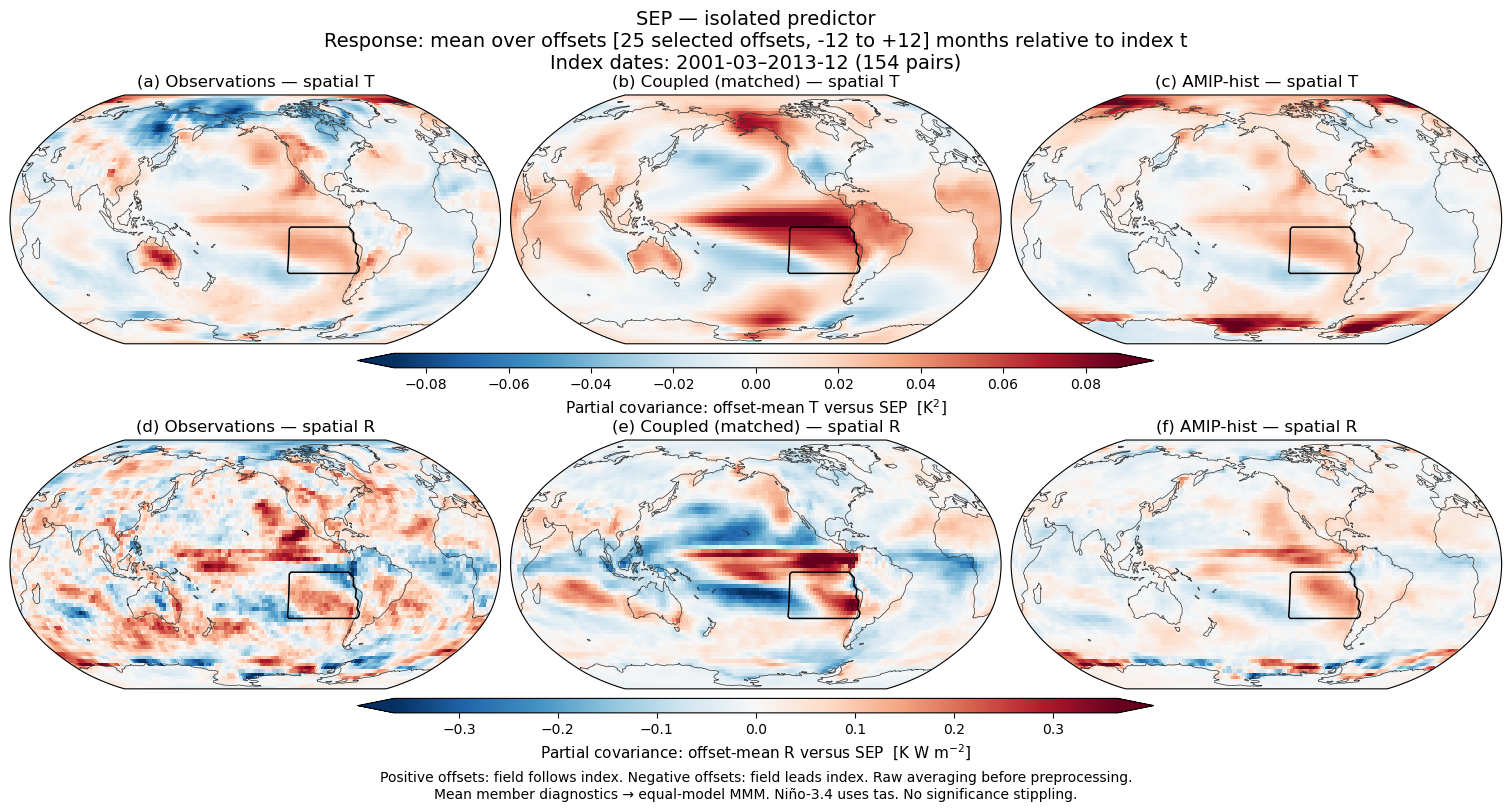

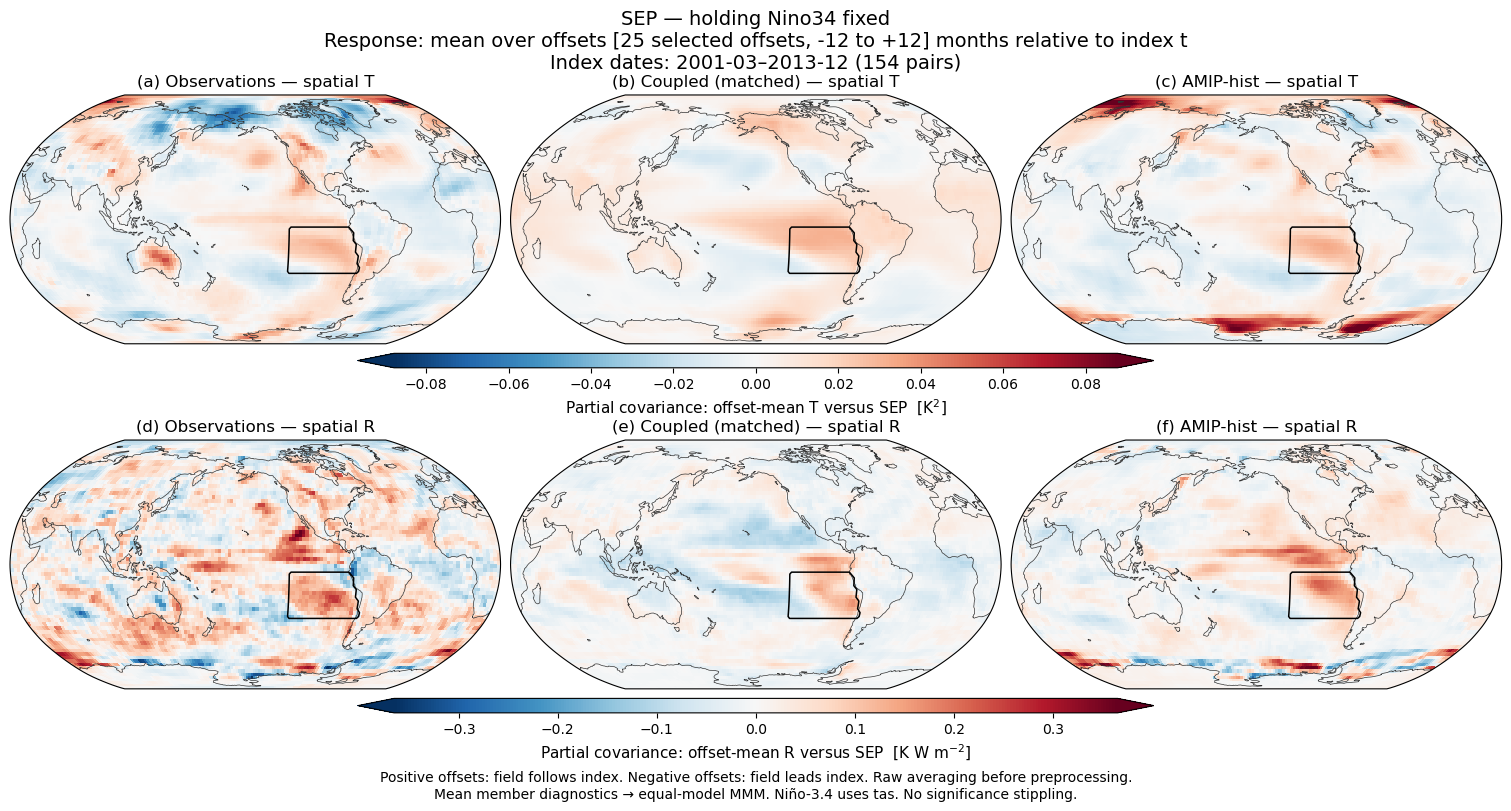

In [29]:
# %% 9. Default figures: all 10 coefficients across the six fit specifications
# Each figure has T/R rows and observations/coupled/AMIP columns. To display
# fewer, set ll_plot_pairs in cell 1 to e.g. [("Nino34_SEP_WPWP", "SEP")].
# PNGs save BEFORE display, so notebook-renderer errors do not lose the plots.
ll_selected_plot_pairs = ([(fit, predictor) for fit, names in ll_archive["fit_predictors"].items() for predictor in names]
                          if ll_plot_pairs is None else ll_plot_pairs)
ll_selected_plot_pairs = [('SEP', 'SEP'),('Nino34_SEP', 'SEP')]
ll_figures, ll_axes = {}, {}
ll_plot_method = "pcolormesh"
ll_plot_statistic = "partial_covariance"  # Instead of "regression".
for fit, predictor in ll_selected_plot_pairs:
    destination = ll_output_dir / f"figures/{fit}_{predictor}_{ll_plot_statistic}.png" if ll_save_figures else None
    ll_figures[fit, predictor], ll_axes[fit, predictor] = plot_regional_lead_lag(
        ll_archive, fit, predictor, statistic=ll_plot_statistic, vlims=ll_plot_vlims,
        cmap=ll_cmap, font_scale=ll_font_scale, savepath=destination,plot_method=ll_plot_method, )
    plt.show()


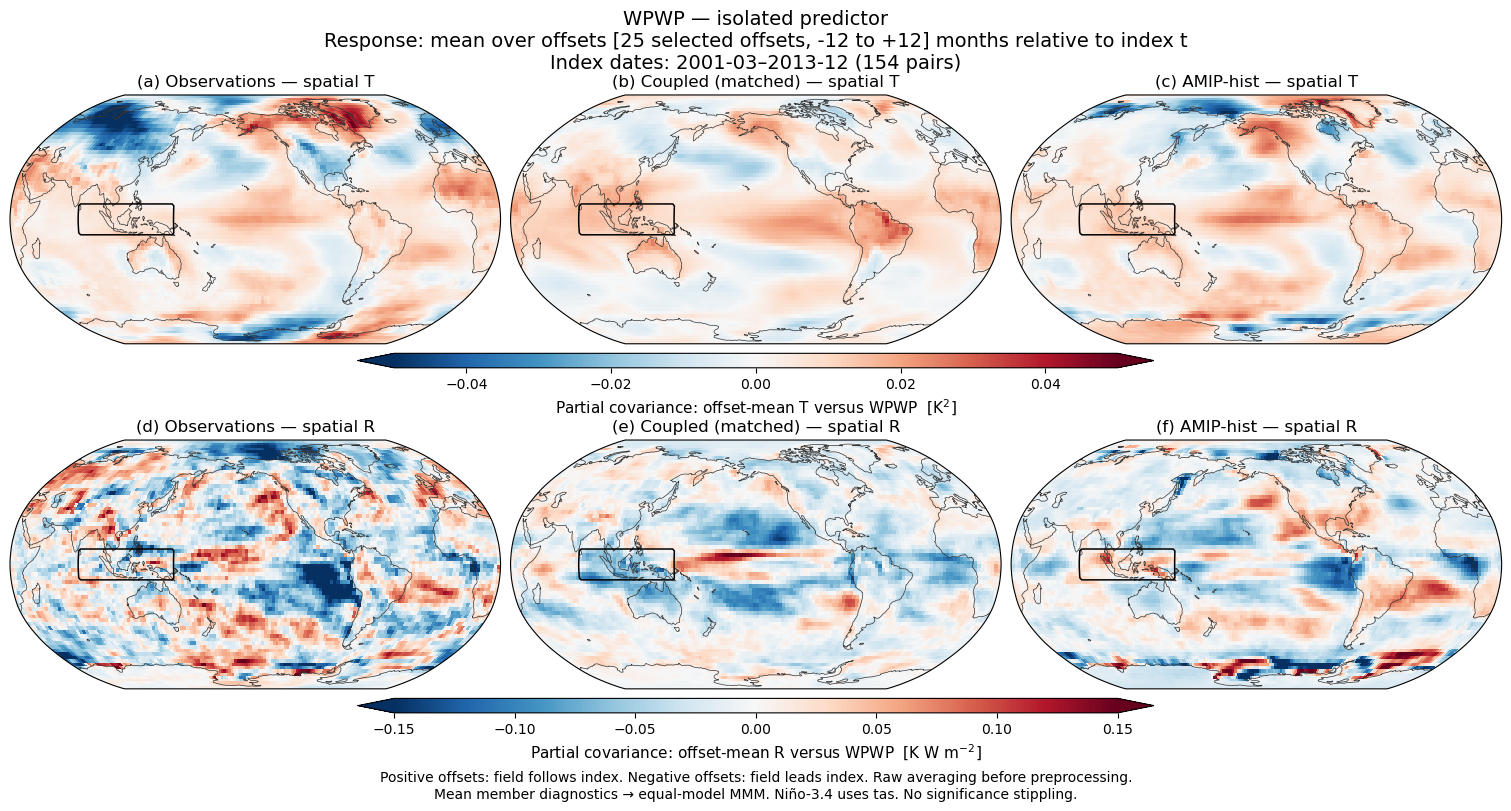

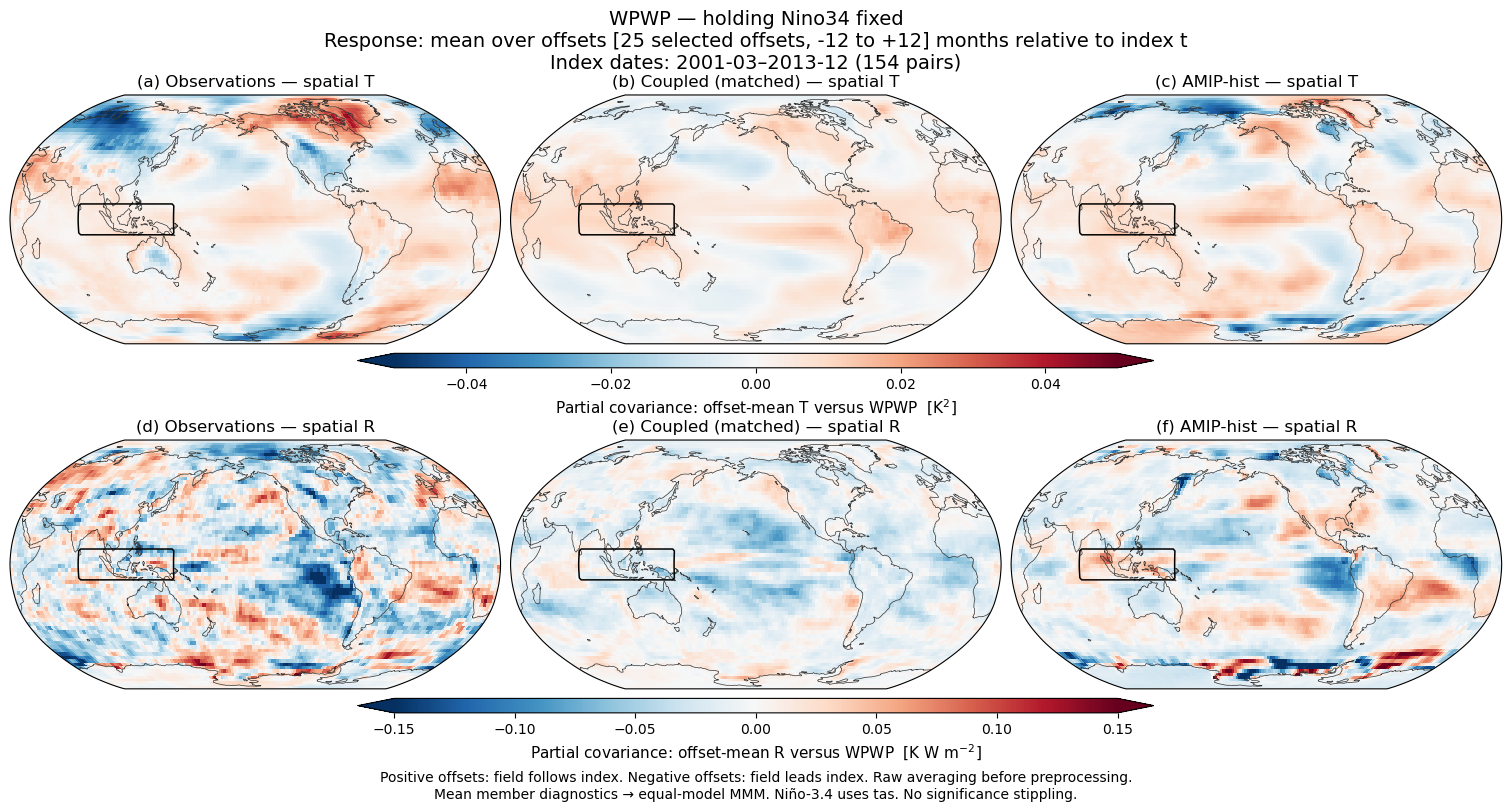

In [32]:
# %% 9. Default figures: all 10 coefficients across the six fit specifications
# Each figure has T/R rows and observations/coupled/AMIP columns. To display
# fewer, set ll_plot_pairs in cell 1 to e.g. [("Nino34_SEP_WPWP", "SEP")].
# PNGs save BEFORE display, so notebook-renderer errors do not lose the plots.
ll_selected_plot_pairs = ([(fit, predictor) for fit, names in ll_archive["fit_predictors"].items() for predictor in names]
                          if ll_plot_pairs is None else ll_plot_pairs)
ll_selected_plot_pairs = [('WPWP', 'WPWP'),('Nino34_WPWP', 'WPWP')]
ll_figures, ll_axes = {}, {}
ll_plot_method = "pcolormesh"
ll_plot_vlims = [0.05,0.15]
ll_plot_statistic = "partial_covariance"  # Instead of "regression".
for fit, predictor in ll_selected_plot_pairs:
    destination = ll_output_dir / f"figures/{fit}_{predictor}_{ll_plot_statistic}.png" if ll_save_figures else None
    ll_figures[fit, predictor], ll_axes[fit, predictor] = plot_regional_lead_lag(
        ll_archive, fit, predictor, statistic=ll_plot_statistic, vlims=ll_plot_vlims,
        cmap=ll_cmap, font_scale=ll_font_scale, savepath=destination,plot_method=ll_plot_method, )
    plt.show()
